In [1]:
!pip -q install pyarrow pandas numpy scikit-learn matplotlib seaborn tensorflow

In [2]:
import pandas as pd
import numpy as np

# Load train and test files
train_df = pd.read_parquet("train-00000-of-00001.parquet")
test_df = pd.read_parquet("test-00000-of-00001.parquet")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (1073851, 42)
Test shape: (268463, 42)


In [3]:
print("Columns in dataset:")
print(train_df.columns.tolist())

print("\nFirst 5 rows:")
display(train_df.head())

Columns in dataset:
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Label', 'attack_class', 'label']

First 5 rows:


,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,...,Max,AVG,Std,Tot size,IAT,Number,Variance,Label,attack_class,label
0,0.00,47,64.00,5779.746173,0.00,0.00,0.00,0.00,0.00,0.0,...,592,592.00,0.000000,592.00,0.000174,100,0.000000,Mirai-greeth_flood,Mirai,1
1,10.20,6,63.36,1974.301113,0.00,0.01,0.01,0.00,0.48,0.0,...,1514,911.92,583.720212,911.92,0.000507,100,340729.286465,DDoS-ACK_Fragmentation,DDoS,1
2,1.00,47,65.23,2090.525036,0.00,0.00,0.00,0.01,0.02,0.0,...,592,566.60,111.302119,566.60,0.000480,100,12388.161616,Mirai-greeth_flood,Mirai,1
3,20.12,6,65.74,26638.958399,0.00,0.99,0.00,0.00,0.01,0.0,...,66,60.06,0.600000,60.06,0.000038,100,0.360000,DDoS-SynonymousIP_Flood,DDoS,1
4,4.00,47,64.42,1854.663960,0.01,0.09,0.01,0.01,0.02,0.0,...,578,512.11,171.336629,512.11,0.000541,100,29356.240303,Mirai-greip_flood,Mirai,1


In [4]:
print("Class distribution in training data:")
print(train_df["attack_class"].value_counts())

print("\nNumber of classes:", train_df["attack_class"].nunique())

print("\nClass names:")
print(train_df["attack_class"].unique())

Class distribution in training data:
attack_class
DDoS          361842
Recon         161877
Benign        159990
DoS           159925
Mirai         119897
Spoofing       80043
Web-based      19820
BruteForce     10457
Name: count, dtype: int64

Number of classes: 8

Class names:
['Mirai' 'DDoS' 'DoS' 'Recon' 'Spoofing' 'Benign' 'Web-based' 'BruteForce']


attack_class

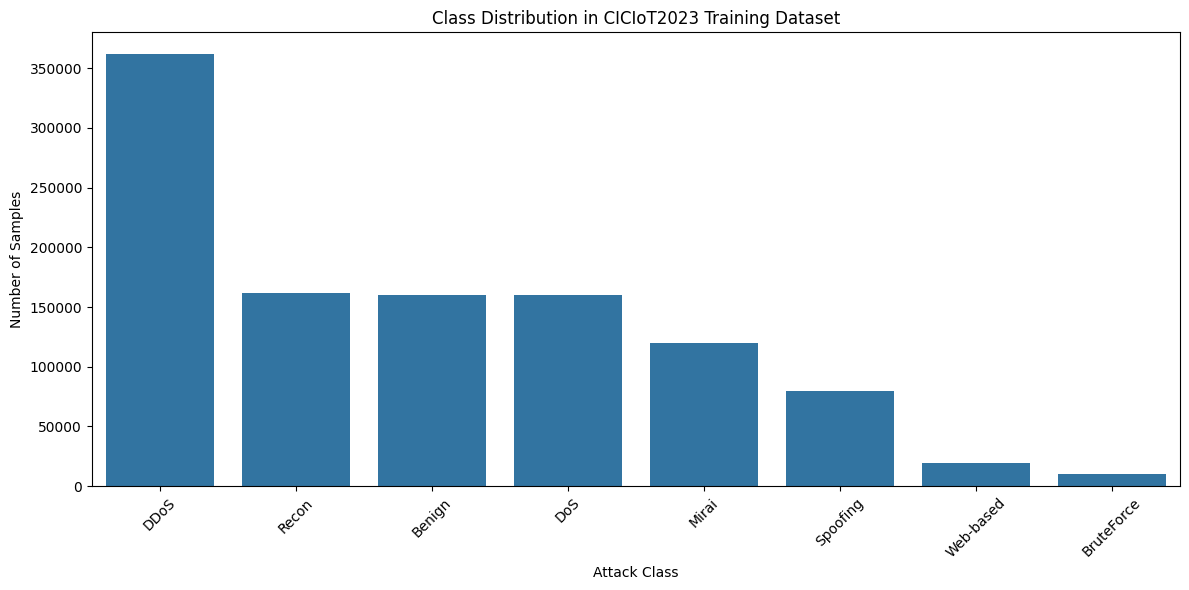

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(
    data=train_df,
    x="attack_class",
    order=train_df["attack_class"].value_counts().index
)

plt.title("Class Distribution in CICIoT2023 Training Dataset")
plt.xlabel("Attack Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
class_distribution = train_df["attack_class"].value_counts()
class_percentage = train_df["attack_class"].value_counts(normalize=True) * 100

distribution_table = pd.DataFrame({
    "Samples": class_distribution,
    "Percentage": class_percentage.round(2)
})

display(distribution_table)

,Samples,Percentage
attack_class,,
DDoS,361842,33.70
Recon,161877,15.07
Benign,159990,14.90
DoS,159925,14.89
Mirai,119897,11.17
Spoofing,80043,7.45
Web-based,19820,1.85
BruteForce,10457,0.97


In [7]:
print("Total missing values:", train_df.isnull().sum().sum())

print("\nMissing values by column:")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])

print("\nDuplicate rows:", train_df.duplicated().sum())

Total missing values: 0

Missing values by column:
Series([], dtype: int64)

Duplicate rows: 84370


In [8]:
print(train_df.dtypes.value_counts())

print("\nNon-numeric columns:")
print(train_df.select_dtypes(exclude=np.number).columns.tolist())

float64    30
int64      10
object      2
Name: count, dtype: int64

Non-numeric columns:
['Label', 'attack_class']


In [9]:
# Remove exact duplicate rows before sampling

before = len(train_df)

train_df_clean = train_df.drop_duplicates().reset_index(drop=True)

after = len(train_df_clean)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)


# Balanced sampling
SAMPLES_PER_CLASS = 10000

balanced_train = (
    train_df_clean
    .groupby("attack_class", group_keys=False)
    .apply(
        lambda x: x.sample(
            n=min(len(x), SAMPLES_PER_CLASS),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

print("\nBalanced dataset shape:", balanced_train.shape)

print("\nNew class distribution:")
print(balanced_train["attack_class"].value_counts())

Rows before removing duplicates: 1073851
Rows after removing duplicates: 989481
Duplicates removed: 84370

Balanced dataset shape: (80000, 42)

New class distribution:
attack_class
Benign        10000
BruteForce    10000
DDoS          10000
DoS           10000
Mirai         10000
Recon         10000
Spoofing      10000
Web-based     10000
Name: count, dtype: int64


/tmp/ipykernel_1681/1912559823.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [10]:
# Target column
target_column = "attack_class"

# Remove ALL label columns from input features
# attack_class = multiclass target
# Label = fine-grained attack label
# label = binary target

X = balanced_train.drop(
    columns=["attack_class", "Label", "label"]
)

y = balanced_train["attack_class"]

# Keep only numerical flow features
X = X.select_dtypes(include=[np.number])

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("Number of input features:", X.shape[1])

Feature shape: (80000, 39)
Target shape: (80000,)
Number of input features: 39


In [11]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:")
for i, class_name in enumerate(label_encoder.classes_):
    print(i, "=", class_name)

Classes:
0 = Benign
1 = BruteForce
2 = DDoS
3 = DoS
4 = Mirai
5 = Recon
6 = Spoofing
7 = Web-based


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

Training samples: 64000
Validation samples: 16000


In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Training data shape:", X_train_scaled.shape)
print("Validation data shape:", X_val_scaled.shape)

Training data shape: (64000, 39)
Validation data shape: (16000, 39)


In [14]:
# Prepare test data

X_test = test_df.drop(
    columns=["attack_class", "Label", "label"]
)

y_test = test_df["attack_class"]

# Keep only numerical flow features
X_test = X_test.select_dtypes(include=[np.number])

# Encode test labels
y_test_encoded = label_encoder.transform(y_test)

# Apply the SAME scaler fitted on training data
X_test_scaled = scaler.transform(X_test)

print("Test feature shape:", X_test_scaled.shape)
print("Test label shape:", y_test_encoded.shape)
print("Number of test features:", X_test_scaled.shape[1])

Test feature shape: (268463, 39)
Test label shape: (268463,)
Number of test features: 39


In [15]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Conv1D, MaxPooling1D
from tensorflow.keras.layers import LSTM, Flatten, BatchNormalization
from tensorflow.keras.layers import Input, MultiHeadAttention, LayerNormalization, GlobalAveragePooling1D, Embedding, Add
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)

print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [16]:
# DNN Baseline Model

num_features = X_train_scaled.shape[1]
num_classes = len(label_encoder.classes_)

dnn_model = Sequential([
    Dense(128, activation="relu", input_shape=(num_features,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax")
])

dnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

dnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,720 (61.41 KB)

 Trainable params: 15,720 (61.41 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
import time

start_time = time.time()

dnn_history = dnn_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=20,
    batch_size=256,
    verbose=1
)

dnn_training_time = time.time() - start_time

print(f"\nDNN Training Time: {dnn_training_time:.2f} seconds")

Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.6074 - loss: 0.9983 - val_accuracy: 0.6537 - val_loss: 0.8379
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6675 - loss: 0.8027 - val_accuracy: 0.6651 - val_loss: 0.8011
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6773 - loss: 0.7800 - val_accuracy: 0.6736 - val_loss: 0.7943
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6826 - loss: 0.7663 - val_accuracy: 0.6777 - val_loss: 0.7758
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6859 - loss: 0.7551 - val_accuracy: 0.6839 - val_loss: 0.7663
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6881 - loss: 0.7477 - val_accuracy: 0.6796 - val_loss: 0.7711
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6923 - loss: 0.7420 - val_accuracy: 0.6873 - val_loss: 0.7534
Epoch 8/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6948 - loss: 0.7339 - val_accuracy: 0

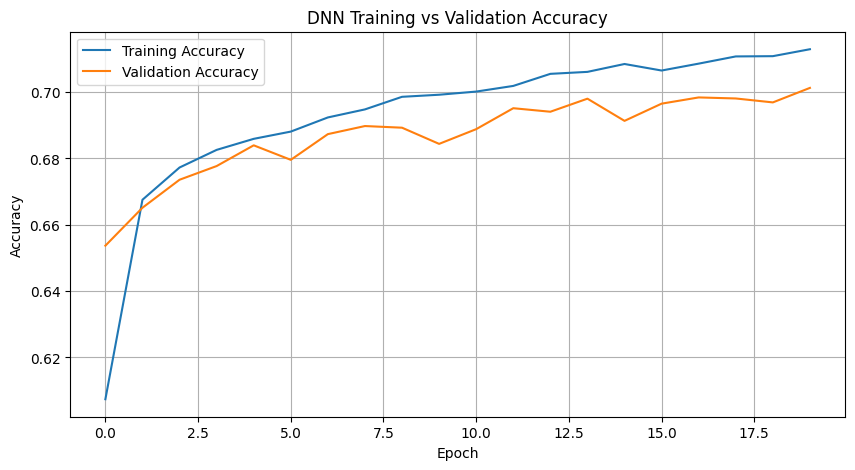

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(dnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(dnn_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("DNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

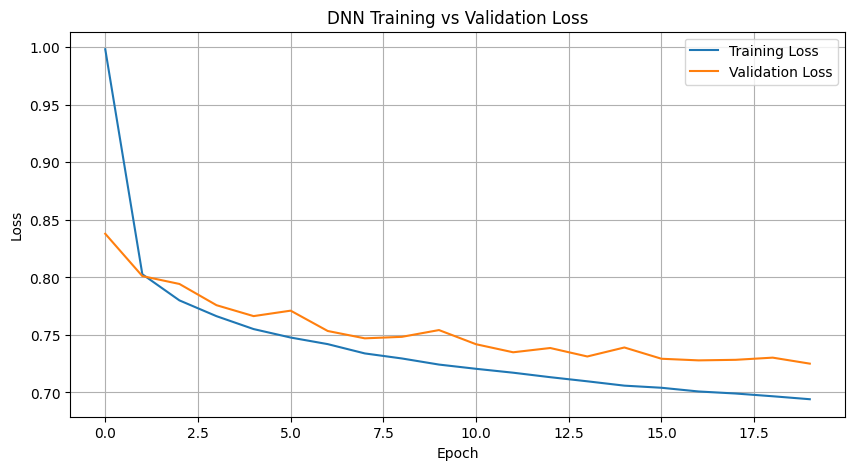

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(dnn_history.history["loss"], label="Training Loss")
plt.plot(dnn_history.history["val_loss"], label="Validation Loss")

plt.title("DNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
# Ablation 1: DNN + Dropout

dropout_dnn = Sequential([
    Dense(128, activation="relu", input_shape=(num_features,)),
    Dropout(0.30),

    Dense(64, activation="relu"),
    Dropout(0.30),

    Dense(32, activation="relu"),

    Dense(num_classes, activation="softmax")
])

dropout_dnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

dropout_dnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,720 (61.41 KB)

 Trainable params: 15,720 (61.41 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Train DNN + Dropout

start_time = time.time()

dropout_history = dropout_dnn.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=20,
    batch_size=256,
    verbose=1
)

dropout_training_time = time.time() - start_time

print(
    f"\nDropout DNN Training Time: "
    f"{dropout_training_time:.2f} seconds"
)

Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5182 - loss: 1.1895 - val_accuracy: 0.6259 - val_loss: 0.8862
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6114 - loss: 0.9138 - val_accuracy: 0.6459 - val_loss: 0.8434
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6319 - loss: 0.8755 - val_accuracy: 0.6572 - val_loss: 0.8208
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6420 - loss: 0.8530 - val_accuracy: 0.6668 - val_loss: 0.8061
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6500 - loss: 0.8342 - val_accuracy: 0.6723 - val_loss: 0.7933
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6557 - loss: 0.8251 - val_accuracy: 0.6747 - val_loss: 0.7844
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6587 - loss: 0.8142 - val_accuracy: 0.6751 - val_loss: 0.7792
Epoch 8/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6623 - loss: 0.8040 - val_accuracy: 0.

In [22]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [23]:
# Ablation 2: DNN + L2 Regularization

from tensorflow.keras.regularizers import l2

l2_dnn = Sequential([
    Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.001),
        input_shape=(num_features,)
    ),

    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dense(32, activation="relu"),

    Dense(num_classes, activation="softmax")
])

l2_dnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

l2_dnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,720 (61.41 KB)

 Trainable params: 15,720 (61.41 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# Train DNN + L2

start_time = time.time()

l2_history = l2_dnn.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=20,
    batch_size=256,
    verbose=1
)

l2_training_time = time.time() - start_time

print(
    f"\nL2 DNN Training Time: "
    f"{l2_training_time:.2f} seconds"
)

Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6080 - loss: 1.1587 - val_accuracy: 0.6473 - val_loss: 0.9680
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6673 - loss: 0.9241 - val_accuracy: 0.6673 - val_loss: 0.9081
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6737 - loss: 0.8857 - val_accuracy: 0.6737 - val_loss: 0.8812
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6790 - loss: 0.8601 - val_accuracy: 0.6674 - val_loss: 0.8631
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6831 - loss: 0.8418 - val_accuracy: 0.6789 - val_loss: 0.8405
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6854 - loss: 0.8285 - val_accuracy: 0.6689 - val_loss: 0.8419
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6879 - loss: 0.8179 - val_accuracy: 0.6769 - val_loss: 0.8288
Epoch 8/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6893 - loss: 0.8082 - val_accuracy: 0.

In [25]:
# Proposed Model: DNN + Dropout + L2

proposed_dnn = Sequential([
    Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.001),
        input_shape=(num_features,)
    ),

    BatchNormalization(),
    Dropout(0.30),

    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.30),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(num_classes, activation="softmax")
])

proposed_dnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

proposed_dnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,232 (63.41 KB)

 Trainable params: 15,976 (62.41 KB)

 Non-trainable params: 256 (1.00 KB)

In [26]:
# Train Proposed Model

early_stop_proposed = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr_proposed = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

start_time = time.time()

proposed_history = proposed_dnn.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=20,
    batch_size=256,
    callbacks=[
        early_stop_proposed,
        reduce_lr_proposed
    ],
    verbose=1
)

proposed_training_time = time.time() - start_time

print(
    f"\nProposed Model Training Time: "
    f"{proposed_training_time:.2f} seconds"
)

Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.4945 - loss: 1.4288 - val_accuracy: 0.6149 - val_loss: 1.0690 - learning_rate: 0.0010
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5925 - loss: 1.0748 - val_accuracy: 0.6354 - val_loss: 0.9689 - learning_rate: 0.0010
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6189 - loss: 1.0033 - val_accuracy: 0.6593 - val_loss: 0.9204 - learning_rate: 0.0010
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6332 - loss: 0.9559 - val_accuracy: 0.6601 - val_loss: 0.8881 - learning_rate: 0.0010
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6437 - loss: 0.9237 - val_accuracy: 0.6693 - val_loss: 0.8644 - learning_rate: 0.0010
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6481 - loss: 0.9033 - val_accuracy: 0.6732 - val_loss: 0.8428 - learning_rate: 0.0010
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6515 - loss: 0.8845 -

In [27]:
X_train_cnn = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_val_cnn = X_val_scaled.reshape(
    X_val_scaled.shape[0],
    X_val_scaled.shape[1],
    1
)

X_test_cnn = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

print("CNN training shape:", X_train_cnn.shape)

CNN training shape: (64000, 39, 1)


In [28]:
cnn_model = Sequential([
    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        input_shape=(num_features, 1)
    ),

    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=128,
        kernel_size=3,
        activation="relu"
    ),

    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.30),

    Dense(num_classes, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 37, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 37, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 18, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 16, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 8, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,448 (615.03 KB)

 Trainable params: 157,320 (614.53 KB)

 Non-trainable params: 128 (512.00 B)

In [29]:
start_time = time.time()

cnn_history = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=20,
    batch_size=256,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

cnn_training_time = time.time() - start_time

print(f"\nCNN Training Time: {cnn_training_time:.2f} seconds")

Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 15s 52ms/step - accuracy: 0.6120 - loss: 0.9643 - val_accuracy: 0.6545 - val_loss: 1.0601 - learning_rate: 0.0010
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 13s 51ms/step - accuracy: 0.6561 - loss: 0.8221 - val_accuracy: 0.6689 - val_loss: 0.8062 - learning_rate: 0.0010
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 21s 55ms/step - accuracy: 0.6680 - loss: 0.7961 - val_accuracy: 0.6773 - val_loss: 0.7774 - learning_rate: 0.0010
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 51ms/step - accuracy: 0.6708 - loss: 0.7826 - val_accuracy: 0.6795 - val_loss: 0.7654 - learning_rate: 0.0010
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 13s 51ms/step - accuracy: 0.6792 - loss: 0.7688 - val_accuracy: 0.6827 - val_loss: 0.7537 - learning_rate: 0.0010
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 46ms/step - accuracy: 0.6850 - loss: 0.7589 - val_accuracy: 0.6893 - val_loss: 0.7494 - learning_rate: 0.0010
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 21s 49ms/step - accuracy: 0.6845 - l

In [30]:
X_train_lstm = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_val_lstm = X_val_scaled.reshape(
    X_val_scaled.shape[0],
    X_val_scaled.shape[1],
    1
)

X_test_lstm = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

In [31]:
lstm_model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(num_features, 1)
    ),

    Dropout(0.30),

    LSTM(32),

    Dropout(0.30),

    Dense(64, activation="relu"),

    Dense(num_classes, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 39, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 39, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,944 (124.78 KB)

 Trainable params: 31,944 (124.78 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
start_time = time.time()

lstm_history = lstm_model.fit(
    X_train_lstm,
    y_train,
    validation_data=(X_val_lstm, y_val),
    epochs=20,
    batch_size=256,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

lstm_training_time = time.time() - start_time

print(f"\nLSTM Training Time: {lstm_training_time:.2f} seconds")

Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 40s 151ms/step - accuracy: 0.3840 - loss: 1.5479 - val_accuracy: 0.4947 - val_loss: 1.2086 - learning_rate: 0.0010
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 50s 199ms/step - accuracy: 0.5033 - loss: 1.1615 - val_accuracy: 0.5368 - val_loss: 1.0835 - learning_rate: 0.0010
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 72s 160ms/step - accuracy: 0.5367 - loss: 1.0844 - val_accuracy: 0.5533 - val_loss: 1.0465 - learning_rate: 5.0000e-04
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 38s 152ms/step - accuracy: 0.5493 - loss: 1.0548 - val_accuracy: 0.5672 - val_loss: 1.0077 - learning_rate: 5.0000e-04
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 40s 149ms/step - accuracy: 0.5656 - loss: 1.0280 - val_accuracy: 0.5771 - val_loss: 0.9866 - learning_rate: 2.5000e-04

LSTM Training Time: 240.64 seconds


## Transformer Encoder Model

A lightweight Transformer encoder is added for tabular network-traffic classification. Each input feature is treated as a token, projected into a learned embedding space, given a trainable positional embedding, and processed using self-attention.

In [33]:
# Prepare Transformer input: one token per traffic feature
X_train_transformer = X_train_scaled[..., np.newaxis]
X_val_transformer = X_val_scaled[..., np.newaxis]
X_test_transformer = X_test_scaled[..., np.newaxis]

print("Transformer training shape:", X_train_transformer.shape)


Transformer training shape: (64000, 39, 1)


In [34]:
class FeaturePositionalEmbedding(tf.keras.layers.Layer):
    def __init__(self, sequence_length, d_model):
        super().__init__()
        self.sequence_length = sequence_length
        self.d_model = d_model
        self.projection = Dense(d_model)
        self.position_embedding = Embedding(
            input_dim=sequence_length,
            output_dim=d_model
        )

    def call(self, inputs):
        positions = tf.range(start=0, limit=self.sequence_length, delta=1)
        positions = self.position_embedding(positions)
        return self.projection(inputs) + positions


def transformer_encoder(x, d_model, num_heads, ff_dim, dropout=0.20):
    # Self-attention block
    attention_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads,
        dropout=dropout
    )(x, x)
    attention_output = Dropout(dropout)(attention_output)
    x = LayerNormalization(epsilon=1e-6)(x + attention_output)

    # Feed-forward block
    ff_output = Dense(ff_dim, activation="gelu")(x)
    ff_output = Dropout(dropout)(ff_output)
    ff_output = Dense(d_model)(ff_output)
    ff_output = Dropout(dropout)(ff_output)
    return LayerNormalization(epsilon=1e-6)(x + ff_output)


d_model = 64
num_heads = 4
ff_dim = 128

transformer_inputs = Input(shape=(num_features, 1), name="traffic_features")
x = FeaturePositionalEmbedding(num_features, d_model)(transformer_inputs)
x = transformer_encoder(x, d_model, num_heads, ff_dim, dropout=0.20)
x = transformer_encoder(x, d_model, num_heads, ff_dim, dropout=0.20)
x = GlobalAveragePooling1D()(x)
x = Dense(64, activation="relu")(x)
x = Dropout(0.30)(x)
transformer_outputs = Dense(num_classes, activation="softmax", name="classification")(x)

transformer_model = Model(transformer_inputs, transformer_outputs, name="Transformer_Classifier")

transformer_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transformer_model.summary()


Model: "Transformer_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ traffic_features    │ (None, 39, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_positional… │ (None, 39, 64)    │      2,624 │ traffic_features… │
│ (FeaturePositional… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 39, 64)    │     16,640 │ feature_position… │
│ (MultiHeadAttentio… │                   │            │ feature_position… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 39, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 39, 64)    │          0 │ feature_position… │
│                     │                   │            │ dropout_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 39, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_21 (Dense)    │ (None, 39, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 39, 128)   │          0 │ dense_21[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_22 (Dense)    │ (None, 39, 64)    │      8,256 │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 39, 64)    │          0 │ dense_22[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 39, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 39, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 39, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 39, 64)    │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 39, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_13[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 39, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_23 (Dense)    │ (None, 39, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 39, 128)   │          0 │ dense_23[0][0]    │
│ (Dropout)           │                   │            │                 

 Total params: 74,248 (290.03 KB)

 Trainable params: 74,248 (290.03 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
# Train Transformer
start_time = time.time()

transformer_history = transformer_model.fit(
    X_train_transformer,
    y_train,
    validation_data=(X_val_transformer, y_val),
    epochs=20,
    batch_size=256,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

transformer_training_time = time.time() - start_time

print(f"\nTransformer Training Time: {transformer_training_time:.2f} seconds")


Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 167s 643ms/step - accuracy: 0.4271 - loss: 1.3616 - val_accuracy: 0.5661 - val_loss: 1.0007 - learning_rate: 0.0010
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 160s 642ms/step - accuracy: 0.5657 - loss: 1.0042 - val_accuracy: 0.6159 - val_loss: 0.9167 - learning_rate: 0.0010
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 160s 641ms/step - accuracy: 0.6099 - loss: 0.9268 - val_accuracy: 0.6227 - val_loss: 0.8745 - learning_rate: 5.0000e-04
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 201s 637ms/step - accuracy: 0.6243 - loss: 0.8957 - val_accuracy: 0.6407 - val_loss: 0.8485 - learning_rate: 5.0000e-04
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 202s 634ms/step - accuracy: 0.6345 - loss: 0.8742 - val_accuracy: 0.6362 - val_loss: 0.8381 - learning_rate: 2.5000e-04

Transformer Training Time: 889.91 seconds


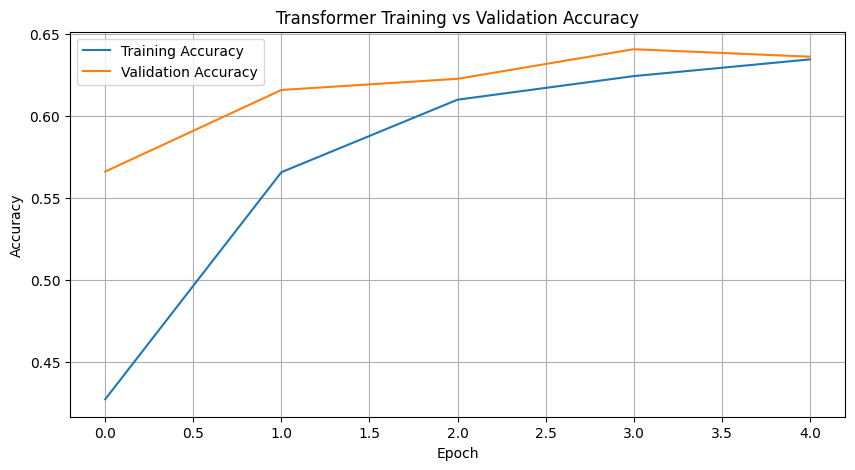

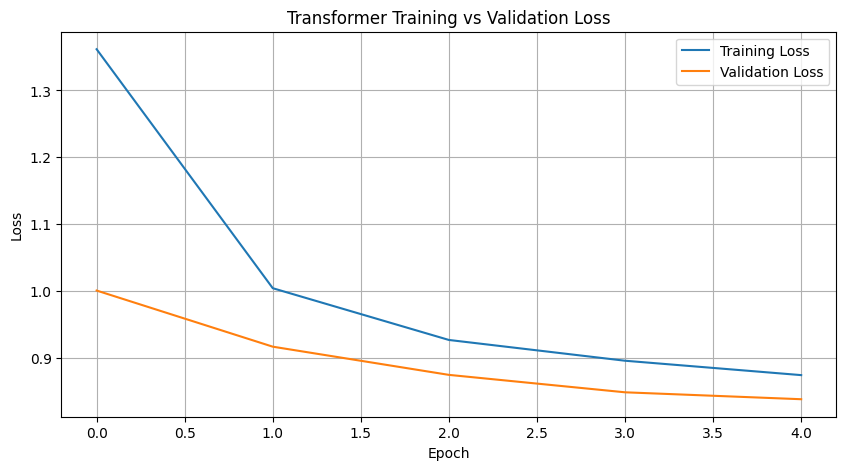

In [36]:
# Transformer training curves
plt.figure(figsize=(10, 5))
plt.plot(transformer_history.history["accuracy"], label="Training Accuracy")
plt.plot(transformer_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Transformer Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(transformer_history.history["loss"], label="Training Loss")
plt.plot(transformer_history.history["val_loss"], label="Validation Loss")
plt.title("Transformer Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predictions

dnn_pred = np.argmax(
    dnn_model.predict(X_test_scaled, verbose=0),
    axis=1
)

dropout_pred = np.argmax(
    dropout_dnn.predict(X_test_scaled, verbose=0),
    axis=1
)

l2_pred = np.argmax(
    l2_dnn.predict(X_test_scaled, verbose=0),
    axis=1
)

proposed_pred = np.argmax(
    proposed_dnn.predict(X_test_scaled, verbose=0),
    axis=1
)

cnn_pred = np.argmax(
    cnn_model.predict(X_test_cnn, verbose=0),
    axis=1
)

lstm_pred = np.argmax(
    lstm_model.predict(X_test_lstm, verbose=0),
    axis=1
)

transformer_pred = np.argmax(
    transformer_model.predict(X_test_transformer, verbose=0),
    axis=1
)

print("All predictions completed.")

All predictions completed.


In [38]:
def calculate_specificity(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)

    specificity = []

    for i in range(len(cm)):
        true_negative = np.sum(cm) - (
            np.sum(cm[i, :]) +
            np.sum(cm[:, i]) -
            cm[i, i]
        )

        false_positive = np.sum(cm[:, i]) - cm[i, i]

        spec = true_negative / (true_negative + false_positive)

        specificity.append(spec)

    return np.mean(specificity)


def evaluate_model(name, y_true, y_pred, training_time):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    specificity = calculate_specificity(
        y_true,
        y_pred
    )

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Specificity": specificity,
        "Training Time (sec)": training_time
    }

In [39]:
results = []

results.append(
    evaluate_model(
        "DNN",
        y_test_encoded,
        dnn_pred,
        dnn_training_time
    )
)

results.append(
    evaluate_model(
        "DNN + Dropout",
        y_test_encoded,
        dropout_pred,
        dropout_training_time
    )
)

results.append(
    evaluate_model(
        "DNN + L2",
        y_test_encoded,
        l2_pred,
        l2_training_time
    )
)

results.append(
    evaluate_model(
        "Proposed DNN",
        y_test_encoded,
        proposed_pred,
        proposed_training_time
    )
)

results.append(
    evaluate_model(
        "1D CNN",
        y_test_encoded,
        cnn_pred,
        cnn_training_time
    )
)

results.append(
    evaluate_model(
        "LSTM",
        y_test_encoded,
        lstm_pred,
        lstm_training_time
    )
)

results.append(
    evaluate_model(
        "Transformer",
        y_test_encoded,
        transformer_pred,
        transformer_training_time
    )
)

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Specificity": "{:.4f}",
        "Training Time (sec)": "{:.2f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,Specificity,Training Time (sec)
0,DNN,0.7530,0.6474,0.6987,0.6349,0.9649,32.37
1,DNN + Dropout,0.7521,0.6389,0.6899,0.6265,0.9645,30.00
2,DNN + L2,0.7388,0.6312,0.6956,0.6246,0.9630,27.66
3,Proposed DNN,0.7446,0.6442,0.6892,0.6235,0.9636,35.10
4,1D CNN,0.7574,0.6494,0.7049,0.6377,0.9655,305.55
5,LSTM,0.5458,0.4950,0.4881,0.4342,0.9358,240.64
6,Transformer,0.6390,0.5690,0.5593,0.5197,0.9485,889.91


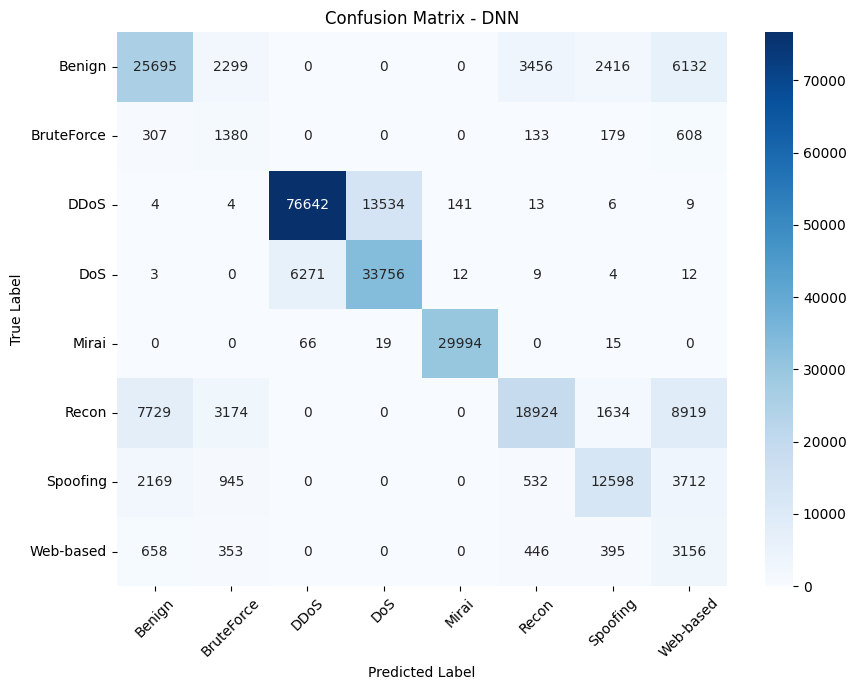

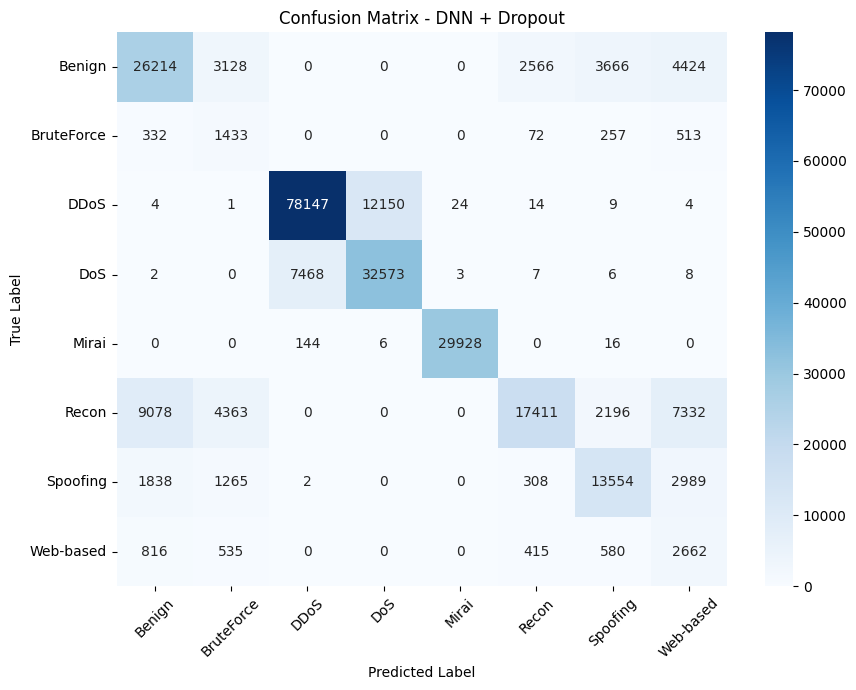

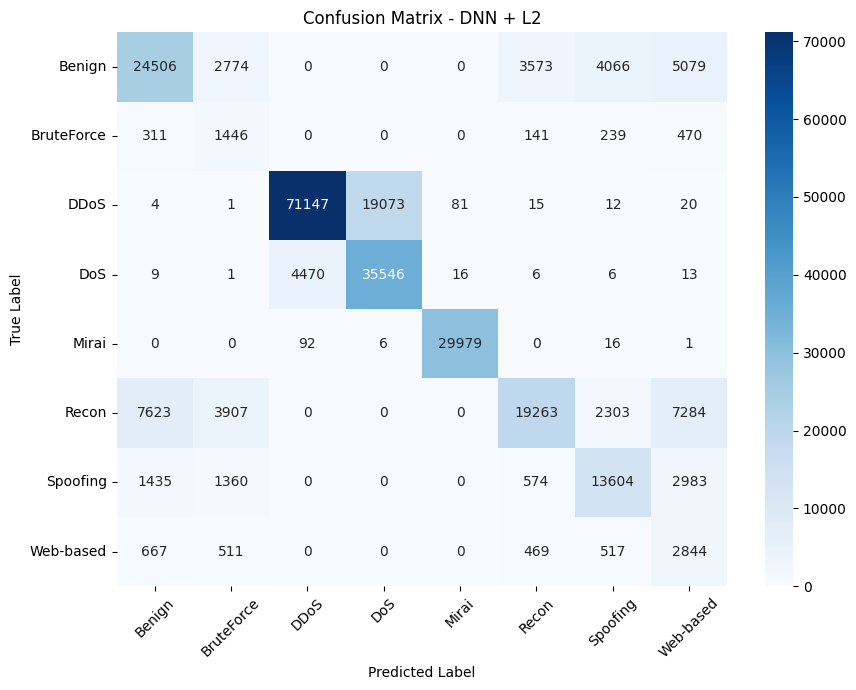

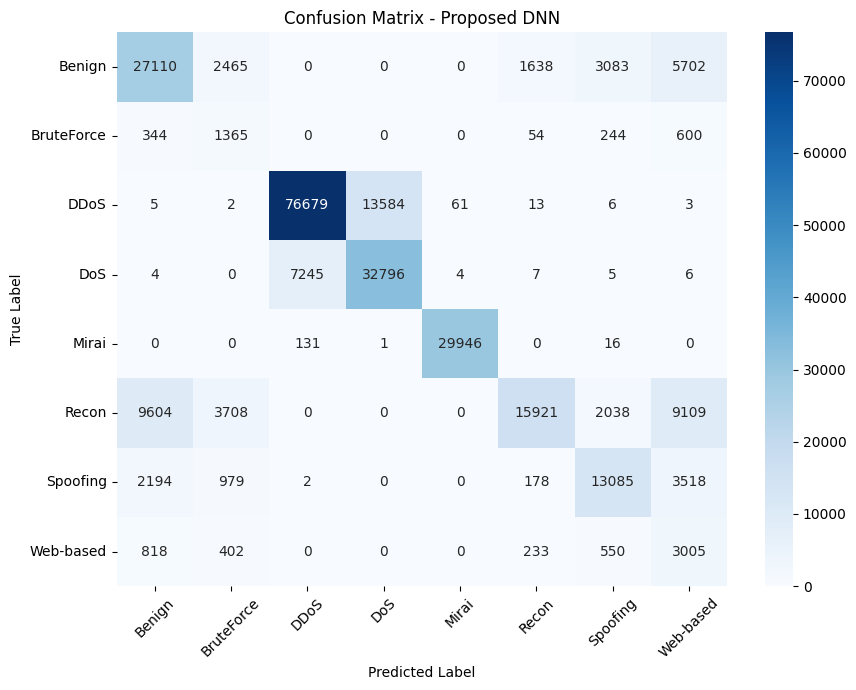

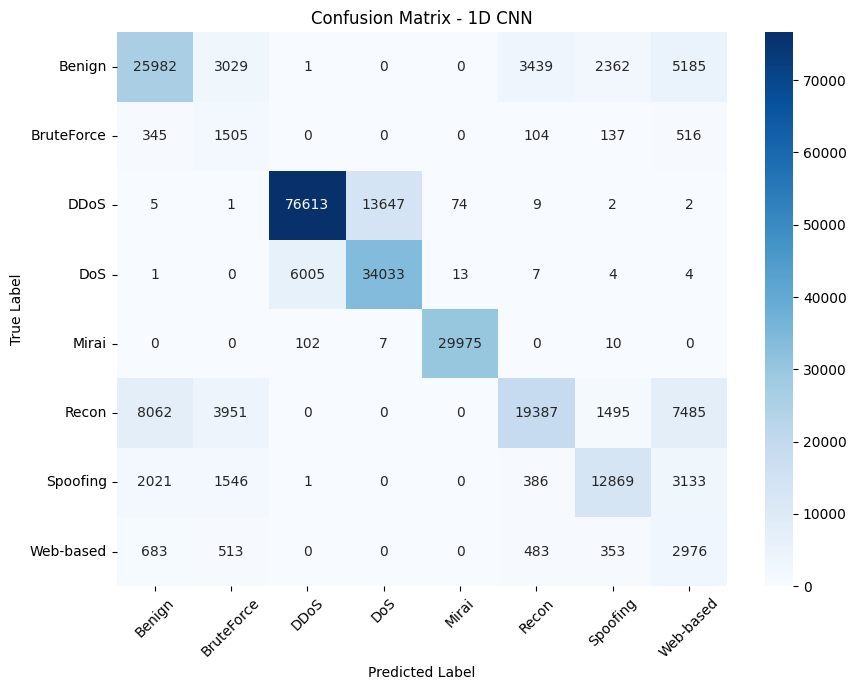

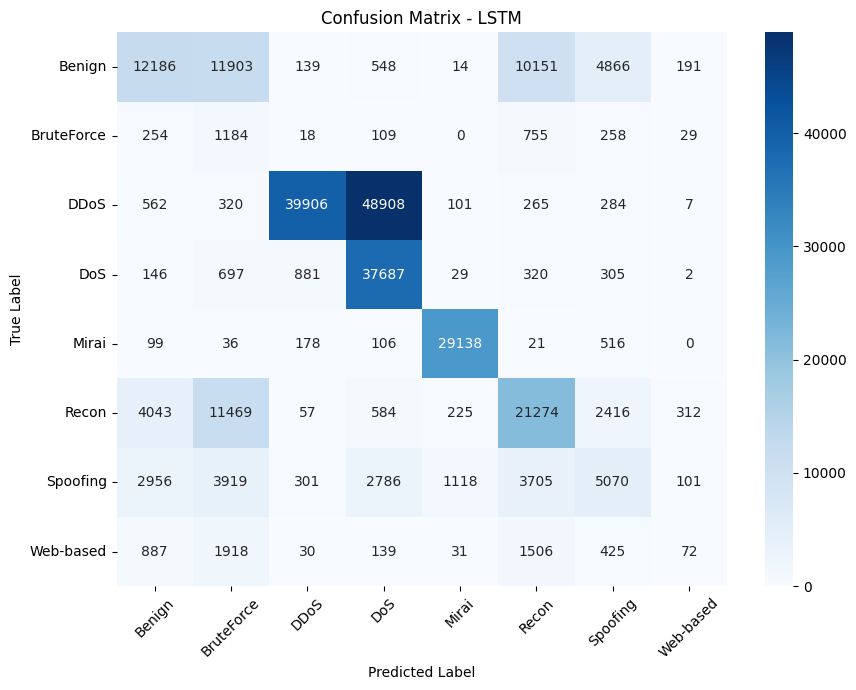

In [40]:
model_predictions = {
    "DNN": dnn_pred,
    "DNN + Dropout": dropout_pred,
    "DNN + L2": l2_pred,
    "Proposed DNN": proposed_pred,
    "1D CNN": cnn_pred,
    "LSTM": lstm_pred,
    "Transformer": transformer_pred
}

for model_name, predictions in model_predictions.items():

    cm = confusion_matrix(
        y_test_encoded,
        predictions
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [41]:
for model_name, predictions in model_predictions.items():

    print("\n" + "="*70)
    print(model_name)
    print("="*70)

    print(
        classification_report(
            y_test_encoded,
            predictions,
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )



DNN
              precision    recall  f1-score   support

      Benign       0.70      0.64      0.67     39998
  BruteForce       0.17      0.53      0.26      2607
        DDoS       0.92      0.85      0.88     90353
         DoS       0.71      0.84      0.77     40067
       Mirai       0.99      1.00      1.00     30094
       Recon       0.80      0.47      0.59     40380
    Spoofing       0.73      0.63      0.68     19956
   Web-based       0.14      0.63      0.23      5008

    accuracy                           0.75    268463
   macro avg       0.65      0.70      0.63    268463
weighted avg       0.81      0.75      0.77    268463


DNN + Dropout
              precision    recall  f1-score   support

      Benign       0.68      0.66      0.67     39998
  BruteForce       0.13      0.55      0.21      2607
        DDoS       0.91      0.86      0.89     90353
         DoS       0.73      0.81      0.77     40067
       Mirai       1.00      0.99      1.00     30094
    

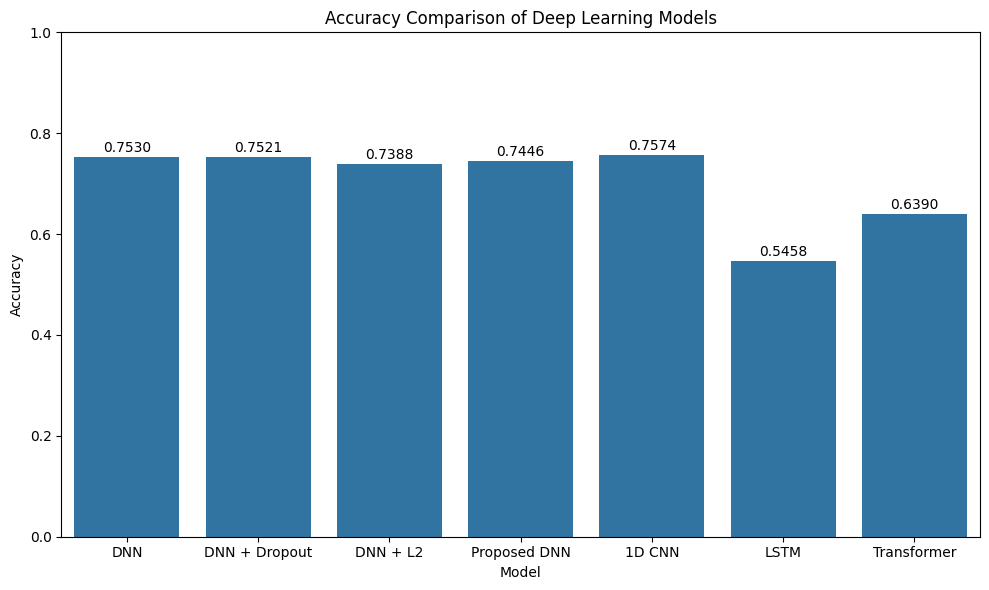

In [42]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Deep Learning Models")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.ylim(0, 1)

for i, value in enumerate(results_df["Accuracy"]):
    plt.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

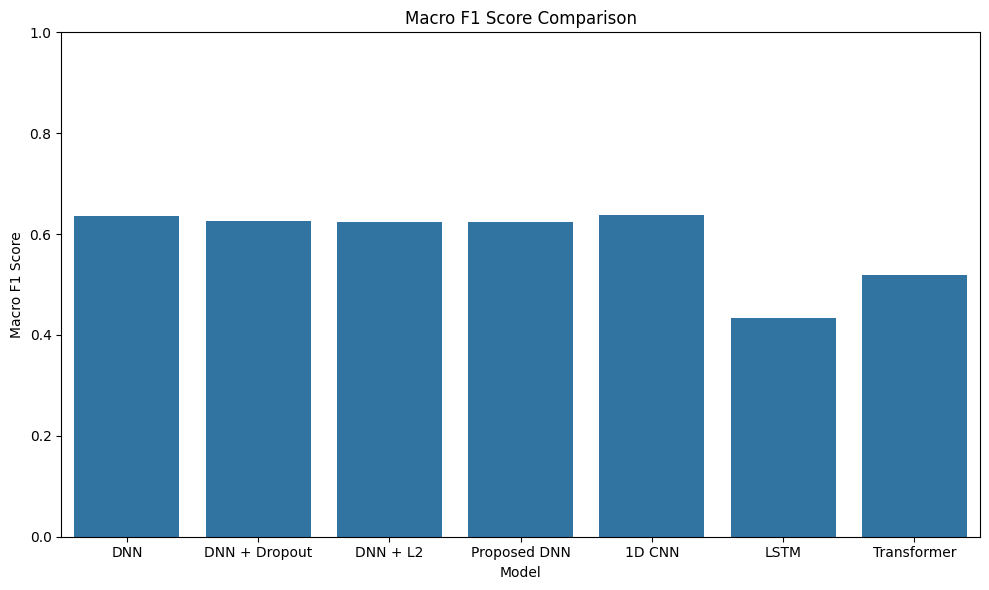

In [43]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("Macro F1 Score Comparison")
plt.ylabel("Macro F1 Score")
plt.xlabel("Model")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

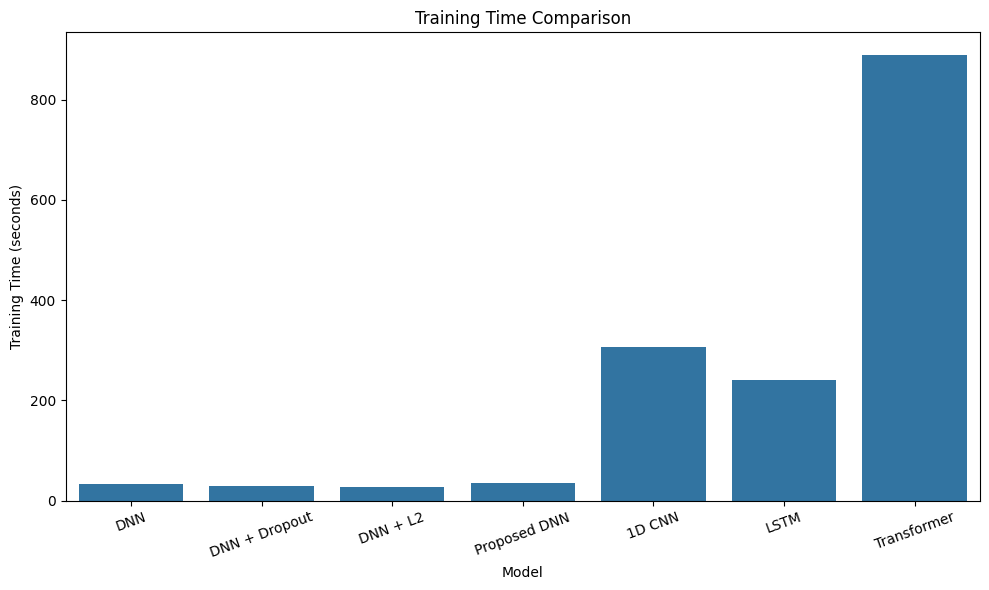

In [44]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Training Time (sec)"
)

plt.title("Training Time Comparison")
plt.ylabel("Training Time (seconds)")
plt.xlabel("Model")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [45]:
results_df.to_csv(
    "CICIoT2023_DL_Model_Comparison.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.
